1. Instalación de librerías

In [12]:
!pip install -q openai langchain langchain-openai langgraph faiss-cpu pypdf sentence-transformers scikit-learn

2. Configuración, imports y conexión con Groq

In [13]:
from google.colab import userdata, files, drive
from openai import OpenAI
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, AIMessage
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from typing import TypedDict, Annotated
from IPython.display import Image, display
import faiss
import numpy as np
import re
import unicodedata
import json
import os

groq_api_key = userdata.get("GROQ_API_KEY")

client = OpenAI(
    api_key=groq_api_key,
    base_url="https://api.groq.com/openai/v1"
)

llm = ChatOpenAI(
    api_key=groq_api_key,
    base_url="https://api.groq.com/openai/v1",
    model="openai/gpt-oss-120b",
    temperature=0.1
)

print("Cliente Groq y modelo LangChain inicializados correctamente")


Cliente Groq y modelo LangChain inicializados correctamente


3. Carga y preparación de documentos

In [3]:
archivos = files.upload()

documentos = []
for nombre_archivo in archivos.keys():
    if nombre_archivo.lower().endswith(".pdf"):
        lector = PdfReader(nombre_archivo)
        texto_completo = ""
        for pagina in lector.pages:
            texto = pagina.extract_text()
            if texto:
                texto_completo += texto + "\n"
        documentos.append({"nombre": nombre_archivo, "texto": texto_completo})


def chunking_text(text, chunk_size=200, overlap=50):
    words = text.split()
    chunks_locales = []
    step = chunk_size - min(overlap, chunk_size - 1)

    for i in range(0, len(words), step):
        chunk = " ".join(words[i:i + chunk_size])
        chunks_locales.append(chunk)
        if i + chunk_size >= len(words):
            break
    return chunks_locales


chunks = []
for documento in documentos:
    for parte in chunking_text(documento["texto"], chunk_size=200, overlap=50):
        chunks.append({"texto": parte, "fuente": documento["nombre"]})

# Refuerzo estructurado para una parte visual de la malla curricular
malla_estructurada = """
Malla curricular de Ingeniería en Informática mención Desarrollo de Software.
La asignatura PPY4616 Práctica Profesional se encuentra en el 8° nivel de la carrera.
"""

chunks.append({
    "texto": malla_estructurada,
    "fuente": "Malla-Curricular-1446116-2024-Ingenieroa-en-Informatica-Especializacion-en-Desarrollo-de-Software-1.pdf"
})

print("Documentos cargados:", len(documentos))
print("Total de chunks:", len(chunks))


Saving Malla-Curricular-1446116-2024-Ingenieroa-en-Informatica-Especializacion-en-Desarrollo-de-Software-1.pdf to Malla-Curricular-1446116-2024-Ingenieroa-en-Informatica-Especializacion-en-Desarrollo-de-Software-1 (1).pdf
Saving NUEVO-REGLAMENTO-ACADEMICO_20260525.pdf to NUEVO-REGLAMENTO-ACADEMICO_20260525 (1).pdf
Saving Reglamento_Titulacion_Duoc_searchable.pdf to Reglamento_Titulacion_Duoc_searchable (1).pdf
Documentos cargados: 3
Total de chunks: 93


4. Embeddings, FAISS y búsqueda híbrida

In [14]:
modelo_embeddings = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

textos_chunks = [chunk["texto"] for chunk in chunks]
embeddings = modelo_embeddings.encode(textos_chunks, convert_to_numpy=True)

indice_faiss = faiss.IndexFlatL2(embeddings.shape[1])
indice_faiss.add(embeddings.astype("float32"))


def limpiar_texto(texto):
    texto = texto.lower()
    texto = unicodedata.normalize("NFD", texto)
    texto = "".join(letra for letra in texto if unicodedata.category(letra) != "Mn")
    texto = re.sub(r"[^a-z0-9\s]", " ", texto)

    palabras_comunes = {
        "el", "la", "los", "las", "un", "una", "unos", "unas",
        "de", "del", "al", "en", "que", "es", "esta", "este",
        "por", "para", "y", "o", "a"
    }
    return [p for p in texto.split() if p not in palabras_comunes]


def buscar_chunks(pregunta, k=5):
    embedding_pregunta = modelo_embeddings.encode([pregunta], convert_to_numpy=True)
    similitudes = cosine_similarity(embedding_pregunta, embeddings)[0]
    palabras_pregunta = set(limpiar_texto(pregunta))
    resultados = []

    for i, chunk in enumerate(chunks):
        palabras_chunk = set(limpiar_texto(chunk["texto"]))
        coincidencias = len(palabras_pregunta.intersection(palabras_chunk))
        puntaje_palabras = coincidencias / max(len(palabras_pregunta), 1)
        puntaje_final = 0.7 * similitudes[i] + 0.3 * puntaje_palabras

        resultados.append({
            "texto": chunk["texto"],
            "fuente": chunk["fuente"],
            "puntaje": puntaje_final
        })

    resultados.sort(key=lambda x: x["puntaje"], reverse=True)
    return resultados[:k]


print("Embeddings:", embeddings.shape)
print("Vectores en FAISS:", indice_faiss.ntotal)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embeddings: (93, 384)
Vectores en FAISS: 93


5. Herramientas del agente

In [5]:
@tool
def consultar_documentos(pregunta: str) -> str:
    """Busca información académica en los documentos de Duoc UC mediante RAG."""
    resultados = buscar_chunks(pregunta, k=5)
    contexto = ""
    for i, resultado in enumerate(resultados, 1):
        contexto += f"""
Documento {i}
Fuente: {resultado['fuente']}

{resultado['texto']}
"""
    return contexto


@tool
def generar_resumen(texto: str) -> str:
    """Genera un resumen breve sin agregar información externa."""
    prompt = f"""
Resume el siguiente contenido de manera breve y clara.

REGLAS:
- Incluye únicamente información relacionada directamente con el tema principal.
- No agregues conclusiones ni consejos.
- No inventes información.
- Omite información secundaria.

CONTENIDO:
{texto}
"""
    return llm.invoke(prompt).content


@tool
def crear_plan_academico(situacion: str) -> str:
    """Crea un plan académico basado únicamente en los documentos recuperados."""
    resultados = buscar_chunks(situacion, k=7)
    contexto = ""
    for i, resultado in enumerate(resultados, 1):
        contexto += f"""
FUENTE {i}: {resultado['fuente']}
{resultado['texto']}
"""

    prompt = f"""
Eres un asistente académico de Duoc UC.
Crea un plan de máximo 6 pasos utilizando EXCLUSIVAMENTE información explícita del contexto.

REGLAS:
- No inventes fechas, oficinas, portales ni procedimientos.
- No deduzcas requisitos que no estén escritos.
- Cada paso debe indicar la fuente que lo respalda.
- Si falta información, indica que el documento no especifica el procedimiento.

SITUACIÓN:
{situacion}

CONTEXTO:
{contexto}
"""
    return llm.invoke(prompt).content


print("Herramientas creadas correctamente")


Herramientas creadas correctamente


6. Memoria persistente y estado del agente

In [6]:
drive.mount('/content/drive')
ruta_memoria = "/content/drive/MyDrive/EduRAG_EVA2_memoria.json"


def cargar_memoria_larga():
    if os.path.exists(ruta_memoria):
        with open(ruta_memoria, "r", encoding="utf-8") as archivo:
            return json.load(archivo)
    return {}


def guardar_memoria_larga(datos):
    with open(ruta_memoria, "w", encoding="utf-8") as archivo:
        json.dump(datos, archivo, ensure_ascii=False, indent=4)


# Crear perfil inicial solo si todavía no existe
memoria_larga = cargar_memoria_larga()
if not memoria_larga:
    memoria_larga = {
        "nombre": "Miguel",
        "carrera": "Ingeniería en Informática",
        "nivel": "8° nivel"
    }
    guardar_memoria_larga(memoria_larga)


class EstadoAgente(TypedDict):
    mensajes: Annotated[list, add_messages]
    intencion: str
    contexto: str
    respuesta: str


print("Memoria persistente configurada:", cargar_memoria_larga())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Memoria persistente configurada: {'nombre': 'Miguel', 'carrera': 'Ingeniería en Informática', 'nivel': '7° nivel'}


7. Lógica de memoria, clasificación y nodos

In [7]:
def actualizar_memoria_desde_mensaje(mensaje):
    memoria = cargar_memoria_larga()
    cambios = {}

    patron_nivel = r"(?:estoy|me encuentro|voy)\s+(?:en\s+)?(?:el\s+)?(\d+)\s*[°º]?\s*nivel"
    coincidencia = re.search(patron_nivel, mensaje.lower())

    if coincidencia:
        nivel = coincidencia.group(1) + "° nivel"
        if memoria.get("nivel") != nivel:
            memoria["nivel"] = nivel
            cambios["nivel"] = nivel

    if cambios:
        guardar_memoria_larga(memoria)

    return cambios


def nodo_actualizar_memoria(estado: EstadoAgente):
    cambios = actualizar_memoria_desde_mensaje(estado["mensajes"][-1].content)
    print("Memoria actualizada:", cambios) if cambios else print("Sin cambios en memoria")
    return {}


def identificar_intencion(estado: EstadoAgente):
    ultimo_mensaje = estado["mensajes"][-1].content
    mensaje_minuscula = ultimo_mensaje.lower()

    patrones_personales = [
        r"estoy\s+(?:en\s+)?(?:el\s+)?\d+\s*[°º]?\s*nivel",
        r"me encuentro\s+(?:en\s+)?(?:el\s+)?\d+\s*[°º]?\s*nivel",
        r"me llamo\s+\w+"
    ]

    if any(re.search(patron, mensaje_minuscula) for patron in patrones_personales):
        intencion = "consulta"
    else:
        prompt = f"""
Clasifica el mensaje en SOLO una categoría: consulta, resumen o plan.
- consulta: pregunta académica o entrega de información personal.
- resumen: pide resumir o sintetizar.
- plan: pide pasos, orientación o planificación.

Mensaje: {ultimo_mensaje}
"""
        intencion = llm.invoke(prompt).content.strip().lower()
        if intencion not in ["consulta", "resumen", "plan"]:
            intencion = "consulta"

    print("Intención detectada:", intencion)
    return {"intencion": intencion}


def nodo_consulta(estado: EstadoAgente):
    ultimo_mensaje = estado["mensajes"][-1].content

    historial = ""
    for mensaje in estado["mensajes"]:
        if isinstance(mensaje, HumanMessage):
            historial += f"Usuario: {mensaje.content}\n"
        elif isinstance(mensaje, AIMessage):
            historial += f"Asistente: {mensaje.content}\n"

    memoria = cargar_memoria_larga()
    perfil = f"Nombre: {memoria.get('nombre', 'No registrado')}\nCarrera: {memoria.get('carrera', 'No registrada')}\nNivel: {memoria.get('nivel', 'No registrado')}"
    contexto = consultar_documentos.invoke(ultimo_mensaje)

    prompt = f"""
Eres EduRAG, un asistente académico de Duoc UC.

REGLAS:
- Usa el historial para continuidad conversacional.
- Usa la memoria persistente para recordar datos del estudiante.
- Usa el contexto documental para información institucional.
- Prioriza información reciente entregada por el usuario.
- No inventes información ni agregues datos no solicitados.
- Responde de forma clara y breve.

HISTORIAL:
{historial}

MEMORIA PERSISTENTE:
{perfil}

PREGUNTA ACTUAL:
{ultimo_mensaje}

CONTEXTO DOCUMENTAL:
{contexto}
"""
    respuesta = llm.invoke(prompt)
    return {"contexto": contexto, "respuesta": respuesta.content, "mensajes": [respuesta]}


def nodo_resumen(estado: EstadoAgente):
    pregunta = estado["mensajes"][-1].content
    contexto = consultar_documentos.invoke(pregunta)

    prompt = f"""
Eres un asistente académico de Duoc UC.
El usuario solicitó: {pregunta}

Resume SOLO la información directamente relacionada con la solicitud.
No agregues conclusiones, consejos ni información externa.

CONTEXTO:
{contexto}
"""
    respuesta = llm.invoke(prompt)
    return {"contexto": contexto, "respuesta": respuesta.content}


def nodo_plan(estado: EstadoAgente):
    situacion = estado["mensajes"][-1].content
    return {"respuesta": crear_plan_academico.invoke(situacion)}


def decidir_ruta(estado: EstadoAgente):
    return estado["intencion"] if estado["intencion"] in ["consulta", "resumen", "plan"] else "consulta"


print("Lógica del agente definida correctamente")


Lógica del agente definida correctamente


8. Construcción final del agente con LangGraph

In [8]:
grafo = StateGraph(EstadoAgente)

grafo.add_node("actualizar_memoria", nodo_actualizar_memoria)
grafo.add_node("identificar_intencion", identificar_intencion)
grafo.add_node("consulta", nodo_consulta)
grafo.add_node("resumen", nodo_resumen)
grafo.add_node("plan", nodo_plan)

grafo.add_edge(START, "actualizar_memoria")
grafo.add_edge("actualizar_memoria", "identificar_intencion")

grafo.add_conditional_edges(
    "identificar_intencion",
    decidir_ruta,
    {"consulta": "consulta", "resumen": "resumen", "plan": "plan"}
)

grafo.add_edge("consulta", END)
grafo.add_edge("resumen", END)
grafo.add_edge("plan", END)

memoria_corta = MemorySaver()
agente = grafo.compile(checkpointer=memoria_corta)

print("Agente EduRAG compilado correctamente")


Agente EduRAG compilado correctamente


9. Evidencia: memoria de corto plazo

In [9]:
config_memoria = {"configurable": {"thread_id": "prueba_memoria_corta"}}

agente.invoke(
    {
        "mensajes": [HumanMessage(content="Mi nombre es Miguel y estoy en 7° nivel de Ingeniería en Informática.")],
        "intencion": "", "contexto": "", "respuesta": ""
    },
    config=config_memoria
)

resultado = agente.invoke(
    {"mensajes": [HumanMessage(content="¿En qué nivel te dije que estoy?")]},
    config=config_memoria
)

print(resultado["respuesta"])


Sin cambios en memoria
Intención detectada: consulta
Sin cambios en memoria
Intención detectada: consulta
Estás en el **7° nivel** de Ingeniería en Informática.


10. Evidencia: memoria de largo plazo entre conversaciones

In [10]:
config_actualizar = {"configurable": {"thread_id": "actualizar_nivel"}}
agente.invoke(
    {
        "mensajes": [HumanMessage(content="Ahora estoy en 7° nivel de Ingeniería en Informática.")],
        "intencion": "", "contexto": "", "respuesta": ""
    },
    config=config_actualizar
)

print("Memoria guardada:", cargar_memoria_larga())

config_nueva = {"configurable": {"thread_id": "conversacion_nueva"}}
resultado = agente.invoke(
    {
        "mensajes": [HumanMessage(content="¿En qué nivel estoy actualmente?")],
        "intencion": "", "contexto": "", "respuesta": ""
    },
    config=config_nueva
)

print("Respuesta en nueva conversación:")
print(resultado["respuesta"])


Sin cambios en memoria
Intención detectada: consulta
Memoria guardada: {'nombre': 'Miguel', 'carrera': 'Ingeniería en Informática', 'nivel': '7° nivel'}
Sin cambios en memoria
Intención detectada: consulta
Respuesta en nueva conversación:
Hola Miguel, según la información que tengo registrada, estás en el **7° nivel** de la carrera de Ingeniería en Informática.


11. Pruebas finales de decisiones adaptativas

In [15]:
import time

pruebas_finales = [
    ("Consulta académica", "¿En qué nivel está la práctica profesional?"),
    ("Resumen académico", "Resume la información sobre la práctica profesional."),
    ("Planificación", "¿Qué debo hacer para realizar mi práctica profesional?"),
    ("Memoria persistente", "¿En qué nivel estoy actualmente?")
]

for i, (nombre, mensaje) in enumerate(pruebas_finales, 1):

    print("\n" + "=" * 65)
    print(nombre)
    print("Pregunta:", mensaje)

    resultado = agente.invoke(
        {
            "mensajes": [
                HumanMessage(content=mensaje)
            ],
            "intencion": "",
            "contexto": "",
            "respuesta": ""
        },
        config={
            "configurable": {
                "thread_id": f"prueba_final_{i}"
            }
        }
    )

    print("Ruta elegida:", resultado["intencion"])
    print("Respuesta:")
    print(resultado["respuesta"])

    # Pausa para evitar superar el límite de Groq
    time.sleep(5)



Consulta académica
Pregunta: ¿En qué nivel está la práctica profesional?
Sin cambios en memoria
Intención detectada: consulta
Ruta elegida: consulta
Respuesta:
La asignatura **PPY4616 Práctica Profesional** se ubica en el **8° nivel** de la carrera de Ingeniería en Informática (mención Desarrollo de Software).

Resumen académico
Pregunta: Resume la información sobre la práctica profesional.
Sin cambios en memoria
Intención detectada: resumen
Ruta elegida: resumen
Respuesta:
**Práctica Profesional – Información resumida**

- **Ubicación curricular**  
  - Asignatura **PPY4616 Práctica Profesional** se sitúa en el **8.º nivel** de la carrera de Ingeniería en Informática, mención Desarrollo de Software. (Doc 3)

- **Duración y créditos**  
  - La práctica debe cursarse según lo establecido en el currículo de la carrera; su duración se determina por el número de créditos indicado en los Planes de Estudio. (Art. 60, Doc 4)

- **Requisitos de inscripción**  
  - La inscripción está supedita

12. Diagrama de orquestación

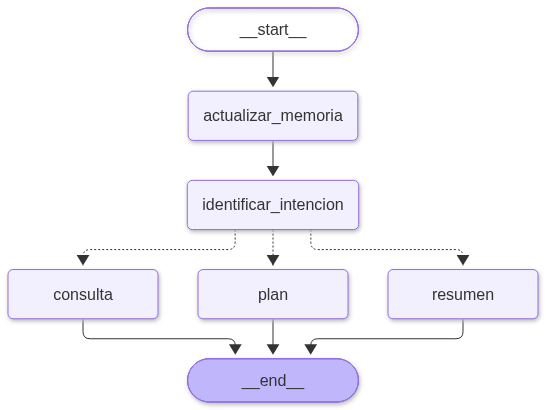

In [14]:
try:
    imagen_grafo = agente.get_graph().draw_mermaid_png()
    display(Image(imagen_grafo))
except Exception as e:
    print("No se pudo generar la imagen automáticamente:", e)
